<a href="https://colab.research.google.com/github/ArtemkaGh0st1k/AIT/blob/feature%2Flab2/lab2/VasilevAS_6231_TAI_Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Васильев Артём
## Лабораторная работа 2
## Вариант 1

## Полносвязная нейронная сеть

Реализовать нейронную сеть, состоящую из двух полносвязных слоев и решающую задачу классификации на наборе данных из лабораторной работы 1.

### Вспомогательные функции

Ранее эти функции импортировались из директории `scripts`
(`data_utils.py`, `gradient_check.py`, `vis_utils.py`). 

In [1]:
import os
import pickle
from math import sqrt, ceil

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


def rel_error(x, y):
    """ returns relative error """
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))


# --- из scripts/gradient_check.py ---
def eval_numerical_gradient(f, x, verbose=True, h=0.00001):
    """
    Численный градиент f в точке x (центральная разность).
    - f: функция от одного аргумента (numpy-массива)
    - x: точка (numpy-массив), в которой считается градиент; меняется "на месте"
    """
    fx = f(x)
    grad = np.zeros_like(x)
    # проходим по всем элементам x
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        ix = it.multi_index
        oldval = x[ix]
        x[ix] = oldval + h      # f(x + h)
        fxph = f(x)
        x[ix] = oldval - h      # f(x - h)
        fxmh = f(x)
        x[ix] = oldval          # восстанавливаем значение

        grad[ix] = (fxph - fxmh) / (2 * h)  # (f(x+h) - f(x-h)) / 2h
        if verbose:
            print(ix, grad[ix])
        it.iternext()
    return grad


# --- из scripts/vis_utils.py ---
def visualize_grid(Xs, ubound=255.0, padding=1):
    """
    Склеивает 4D-тензор изображений (N, H, W, C) в одну картинку-сетку.
    Каждое изображение нормируется в диапазон [0, ubound].
    """
    (N, H, W, C) = Xs.shape
    grid_size = int(ceil(sqrt(N)))
    grid_height = H * grid_size + padding * (grid_size - 1)
    grid_width = W * grid_size + padding * (grid_size - 1)
    grid = np.zeros((grid_height, grid_width, C))
    next_idx = 0
    y0, y1 = 0, H
    for y in range(grid_size):
        x0, x1 = 0, W
        for x in range(grid_size):
            if next_idx < N:
                img = Xs[next_idx]
                low, high = np.min(img), np.max(img)
                grid[y0:y1, x0:x1] = ubound * (img - low) / (high - low)
                next_idx += 1
            x0 += W + padding
            x1 += W + padding
        y0 += H + padding
        y1 += H + padding
    return grid


# --- из scripts/data_utils.py ---
def load_CIFAR_batch(filename):
    """ загрузка одного батча CIFAR-10 (pickle-файл на 10 000 картинок) """
    with open(filename, 'rb') as f:
        datadict = pickle.load(f, encoding='latin1')
        X = datadict['data']
        Y = datadict['labels']
        # (10000, 3072) -> (10000, 3, 32, 32) -> (10000, 32, 32, 3)
        X = X.reshape(10000, 3, 32, 32).transpose(0, 2, 3, 1).astype('float')
        Y = np.array(Y)
        return X, Y


def load_CIFAR10(ROOT):
    """ загрузка всего CIFAR-10: data_batch_1..5 (50 000) + test_batch (10 000) """
    xs, ys = [], []
    for b in range(1, 6):
        X, Y = load_CIFAR_batch(os.path.join(ROOT, 'data_batch_%d' % b))
        xs.append(X)
        ys.append(Y)
    Xtr = np.concatenate(xs)
    Ytr = np.concatenate(ys)
    Xte, Yte = load_CIFAR_batch(os.path.join(ROOT, 'test_batch'))
    return Xtr, Ytr, Xte, Yte

### Реализация класса `TwoLayerNet`

In [ ]:
import numpy as np

class TwoLayerNet(object):
    """
    A two-layer fully-connected neural network. The net has an input dimension of
    N, a hidden layer dimension of H, and performs classification over C classes.
    We train the network with a softmax loss function and L2 regularization on the
    weight matrices. The network uses a ReLU nonlinearity after the first fully
    connected layer.

    In other words, the network has the following architecture:

    input - fully connected layer - ReLU - fully connected layer - softmax

    The outputs of the second fully-connected layer are the scores for each class.
    """

    def __init__(self, input_size, hidden_size, output_size, std=1e-4):
        """
        Initialize the model. Weights are initialized to small random values and
        biases are initialized to zero. Weights and biases are stored in the
        variable self.params, which is a dictionary with the following keys:

        W1: First layer weights; has shape (D, H)
        b1: First layer biases; has shape (H,)
        W2: Second layer weights; has shape (H, C)
        b2: Second layer biases; has shape (C,)

        Inputs:
        - input_size: The dimension D of the input data.
        - hidden_size: The number of neurons H in the hidden layer.
        - output_size: The number of classes C.
        """
        self.params = {}
        self.params['W1'] = std * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)

    def loss(self, X, y=None, reg=0.0):
        """
        Compute the loss and gradients for a two layer fully connected neural
        network.

        Inputs:
        - X: Input data of shape (N, D). Each X[i] is a training sample.
        - y: Vector of training labels. y[i] is the label for X[i], and each y[i] is
          an integer in the range 0 <= y[i] < C. This parameter is optional; if it
          is not passed then we only return scores, and if it is passed then we
          instead return the loss and gradients.
        - reg: Regularization strength.

        Returns:
        If y is None, return a matrix scores of shape (N, C) where scores[i, c] is
        the score for class c on input X[i].

        If y is not None, instead return a tuple of:
        - loss: Loss (data loss and regularization loss) for this batch of training
          samples.
        - grads: Dictionary mapping parameter names to gradients of those parameters
          with respect to the loss function; has the same keys as self.params.
        """
        # Unpack variables from the params dictionary
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']
        N, D = X.shape

        # Compute the forward pass
        scores = None

        z1 = X.dot(W1) + b1       # первый линейный слой
        a1 = np.maximum(0, z1)    # ReLU

        scores = a1.dot(W2) + b2  # второй линейный слой

        # If the targets are not given then jump out, we're done
        if y is None:
            return scores

        # Compute the loss
        loss = None

        # стабильный softmax: вычитаем максимум для
        # предотвращения числ. перепол
        shifted_scores = scores - np.max(scores, axis=1, keepdims=True)
        exp_scores = np.exp(shifted_scores)
        probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

        # вычисление data loss (cross-entropy loss)
        correct_logprobs = -np.log(probs[np.arange(N), y])
        data_loss = np.sum(correct_logprobs) / N

        # L2-регуляризация
        reg_loss = reg * (np.sum(W1 * W1) + np.sum(W2 * W2))

        # итоговая функция потерь
        loss = data_loss + reg_loss

        # Backward pass: compute gradients
        grads = {}

        # градиенты относительно скоров
        dscores = probs.copy()
        dscores[np.arange(N), y] -= 1.0
        dscores /= N

        # градиенты для второго слоя
        grads['W2'] = a1.T.dot(dscores) + 2 * reg * W2
        grads['b2'] = np.sum(dscores, axis=0)

        da1 = dscores.dot(W2.T)   # градиент обр прохода через 2й слой к скрытому a1
        dz1 = da1 * (z1 > 0)      # градиент обратного прохода через ReLU

        # градиенты для первго слоя
        grads['W1'] = X.T.dot(dz1) + 2 * reg * W1
        grads['b1'] = np.sum(dz1, axis=0)

        return loss, grads

    def train(self, X, y, X_val, y_val,
              learning_rate=1e-3, learning_rate_decay=0.95,
              reg=5e-6, num_iters=100,
              batch_size=200, verbose=False):
        """
        Train this neural network using stochastic gradient descent.

        Inputs:
        - X: A numpy array of shape (N, D) giving training data.
        - y: A numpy array f shape (N,) giving training labels; y[i] = c means that
          X[i] has label c, where 0 <= c < C.
        - X_val: A numpy array of shape (N_val, D) giving validation data.
        - y_val: A numpy array of shape (N_val,) giving validation labels.
        - learning_rate: Scalar giving learning rate for optimization.
        - learning_rate_decay: Scalar giving factor used to decay the learning rate
          after each epoch.
        - reg: Scalar giving regularization strength.
        - num_iters: Number of steps to take when optimizing.
        - batch_size: Number of training examples to use per step.
        - verbose: boolean; if true print progress during optimization.
        """
        num_train = X.shape[0]
        iterations_per_epoch = max(num_train // batch_size, 1)

        # Use SGD to optimize the parameters in self.model
        loss_history = []
        train_acc_history = []
        val_acc_history = []

        for it in range(num_iters):
            X_batch = None
            y_batch = None

            # случайный мини-батч из batch_size объектов (с возвращением -
            # так быстрее и работает даже если batch_size > num_train)
            batch_idx = np.random.choice(num_train, batch_size, replace=True)
            X_batch = X[batch_idx]
            y_batch = y[batch_idx]

            # Compute loss and gradients using the current minibatch
            loss, grads = self.loss(X_batch, y=y_batch, reg=reg)
            loss_history.append(loss)

            # шаг SGD: двигаем каждый параметр против градиента
            for param_name in self.params:
                self.params[param_name] -= learning_rate * grads[param_name]

            if verbose and it % 100 == 0:
                print('iteration %d / %d: loss %f' % (it, num_iters, loss))

            # Every epoch, check train and val accuracy and decay learning rate.
            if it % iterations_per_epoch == 0:
                # Check accuracy
                train_acc = (self.predict(X_batch) == y_batch).mean()
                val_acc = (self.predict(X_val) == y_val).mean()
                train_acc_history.append(train_acc)
                val_acc_history.append(val_acc)

                # Decay learning rate
                learning_rate *= learning_rate_decay

        return 
        {
          'loss_history': loss_history,
          'train_acc_history': train_acc_history,
          'val_acc_history': val_acc_history,
        }

    def predict(self, X):
        """
        Use the trained weights of this two-layer network to predict labels for
        data points. For each data point we predict scores for each of the C
        classes, and assign each data point to the class with the highest score.

        Inputs:
        - X: A numpy array of shape (N, D) giving N D-dimensional data points to
          classify.

        Returns:
        - y_pred: A numpy array of shape (N,) giving predicted labels for each of
          the elements of X. For all i, y_pred[i] = c means that X[i] is predicted
          to have class c, where 0 <= c < C.
        """
        y_pred = None

        # прямой проход без y возвращает scores, берём класс с макс. оценкой
        scores = self.loss(X)
        y_pred = np.argmax(scores, axis=1)

        return y_pred

1. Добавьте реализации методов класса TwoLayerNet . Проверьте вашу реализацию на модельных данных (Код приведен ниже).  

In [3]:
input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

# Прямой проход: вычисление выхода сети

Реализуйте первую часть  метода TwoLayerNet.loss, вычисляющую оценки классов для входных данных.

Сравните ваш выход сети с эталонными значениями. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-7) .

In [4]:
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
  [-0.81233741, -1.27654624, -0.70335995],
  [-0.17129677, -1.18803311, -0.47310444],
  [-0.51590475, -1.01354314, -0.8504215 ],
  [-0.15419291, -0.48629638, -0.52901952],
  [-0.00618733, -0.12435261, -0.15226949]])
print(correct_scores)
print()


print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))

Your scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

correct scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

Difference between your scores and correct scores:
3.6802720745909845e-08



# Прямой проход: вычисление loss

Реализуйте вторую часть метода, вычисляющую значение функции потерь. Сравните с эталоном. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-12) .

In [5]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.30378789133

print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))

Difference between your loss and correct loss:
1.7985612998927536e-13


# Обратный проход

Реализуйте третью часть метода loss. Используйте численную реализацию расчета градиента для проверки вашей реализации обратного прохода.  Если прямой и обратный проходы реализованы верно, то ошибка будет < 1e-8 для каждой из переменных W1, W2, b1, и b2.


In [6]:
loss, grads = net.loss(X, y, reg=0.05)

# сравниваем аналитический градиент с численным для каждого параметра
for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W2 max relative error: 3.440708e-09
b2 max relative error: 4.447625e-11
W1 max relative error: 3.561318e-09
b1 max relative error: 2.738421e-09


# Обучение нейронной сети на смоделированных данных

Реализуйте методы TwoLayerNet.train и TwoLayerNet.predict. Обучайте сеть до тех пор, пока значение loss не будет < 0.02.


Final training loss:  0.017149607938732093


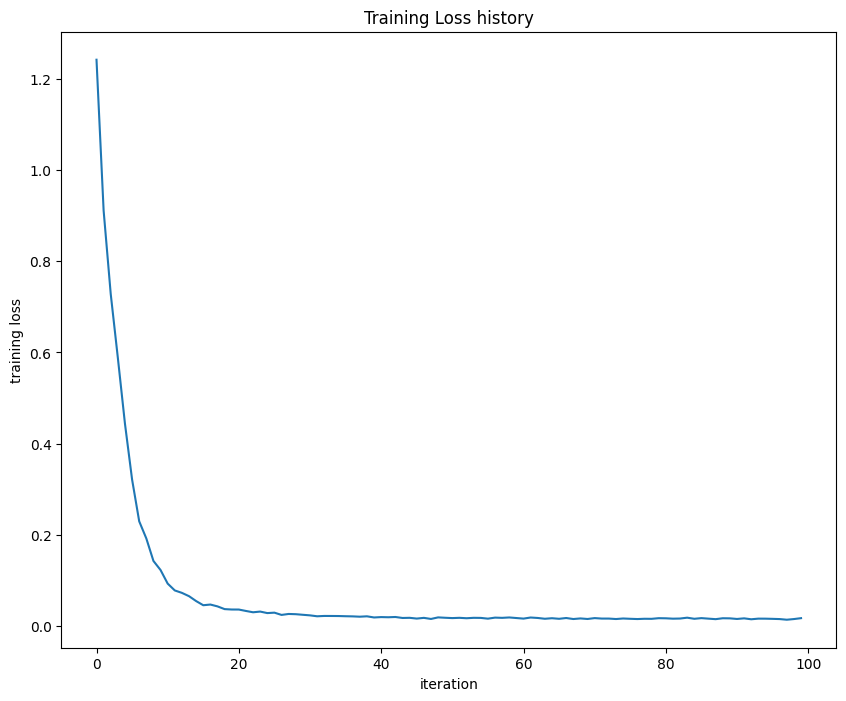

In [7]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=5e-6,
            num_iters=100, verbose=False)

print('Final training loss: ', stats['loss_history'][-1])


plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

# Обучение нейронной сети на реальном наборе данных (CIFAR-10, MNIST)

Загрузите набор данных, соответствующий вашему варианту.

Разделите данные на обучающую, тестовую и валидационную выборки.

Выполните предобработку данных, как в ЛР 1.

Обучите нейронную сеть на ваших данных.

При сдаче лабораторной работы объясните значения всех параметров метода train.

### Загрузка и предобработка CIFAR-10 (вариант 1)

Как в ЛР 1: делим данные на обучающую (49 000), валидационную (1 000) и тестовую (1 000) выборки,
вытягиваем изображения в векторы длины 3072 и вычитаем среднее изображение обучающей выборки.
Столбец единиц (bias trick) здесь не нужен - у сети есть свои смещения `b1`, `b2`.

In [ ]:
cifar10_dir = os.path.join('..', '..', 'cifar-10-python', 'cifar-10-batches-py')

X_train_all, y_train_all, X_test_all, y_test_all = load_CIFAR10(cifar10_dir)

num_training, num_validation, num_test = 49000, 1000, 1000

# в батчах CIFAR-10 картинки уже перемешаны, поэтому делим подряд:
# train - первые 49 000, val - следующие 1 000, test - первые 1 000 из test_batch
X_val = X_train_all[num_training:num_training + num_validation]
y_val = y_train_all[num_training:num_training + num_validation]
X_train = X_train_all[:num_training]
y_train = y_train_all[:num_training]
X_test = X_test_all[:num_test]
y_test = y_test_all[:num_test]
del X_train_all, y_train_all, X_test_all, y_test_all

# (N, 32, 32, 3) -> (N, 3072)
X_train = X_train.reshape(num_training, -1)
X_val = X_val.reshape(num_validation, -1)
X_test = X_test.reshape(num_test, -1)

# вычитаем среднее изображение (считается только по train!)
mean_image = np.mean(X_train, axis=0)
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image

print('Train data shape:      ', X_train.shape)
print('Validation data shape: ', X_val.shape)
print('Test data shape:       ', X_test.shape)

Train data shape:       (49000, 3072)
Validation data shape:  (1000, 3072)
Test data shape:        (1000, 3072)


#### Обучение с параметрами по умолчанию

Параметры метода `train`:
- `X, y` - обучающие данные и метки;
- `X_val, y_val` - валидационные данные, на них раз в эпоху считается accuracy;
- `learning_rate` - шаг градиентного спуска (насколько сильно меняются веса за итерацию);
- `learning_rate_decay` - множитель, на который уменьшается шаг после каждой эпохи;
- `reg` - сила L2-регуляризации (штраф за большие веса, борется с переобучением);
- `num_iters` - число итераций (шагов SGD);
- `batch_size` - размер мини-батча, по которому считается градиент на одной итерации;
- `verbose` - печатать ли loss каждые 100 итераций.

In [9]:
input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
np.random.seed(0)
net = TwoLayerNet(input_size, hidden_size, num_classes)

stats = net.train(X_train, y_train, X_val, y_val,
            num_iters=1000, batch_size=200,
            learning_rate=1e-4, learning_rate_decay=0.95,
            reg=0.25, verbose=True)

val_acc = (net.predict(X_val) == y_val).mean()
print('Validation accuracy: ', val_acc)

baseline_net = net  # сохраним, чтобы потом сравнить с лучшей моделью

iteration 0 / 1000: loss 2.302976
iteration 100 / 1000: loss 2.302638
iteration 200 / 1000: loss 2.299256
iteration 300 / 1000: loss 2.270635
iteration 400 / 1000: loss 2.219117
iteration 500 / 1000: loss 2.141064
iteration 600 / 1000: loss 2.129066
iteration 700 / 1000: loss 2.047454
iteration 800 / 1000: loss 1.988162
iteration 900 / 1000: loss 1.967131
Validation accuracy:  0.282


Используя параметры по умолчанию, вы можете получить accuracy, примерно равный 0.29.

Проведите настройку гиперпараметров для увеличения accuracy. Поэкспериментируйте со значениями гиперпараметров, например, с количеством скрытых слоев, количеством эпох, скорости обучения и др. Ваша цель - максимально увеличить accuracy полносвязной сети на валидационном наборе. Различные эксперименты приветствуются. Например, вы можете использовать методы для сокращения размерности признакового пространства (например, PCA), добавить dropout слои и др.

Для лучшей модели вычислите acсuracy на тестовом наборе.

Для отладки процесса обучения часто помогают графики изменения loss и accuracy в процессе обучения. Ниже приведен код построения таких графиков.

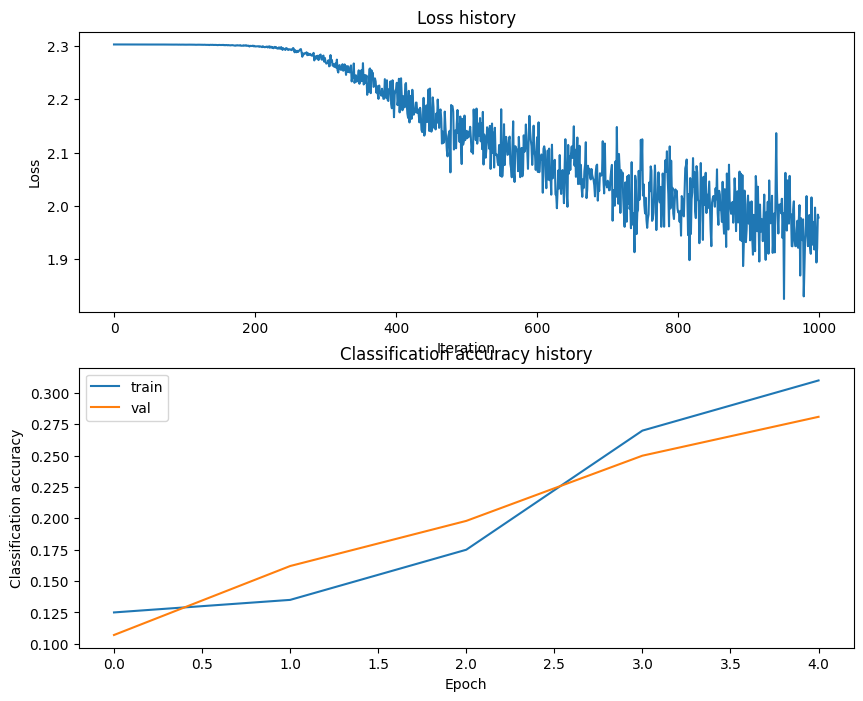

In [10]:
plt.subplot(2, 1, 1)
plt.plot(stats['loss_history'])
plt.title('Loss history')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(stats['train_acc_history'], label='train')
plt.plot(stats['val_acc_history'], label='val')
plt.title('Classification accuracy history')
plt.xlabel('Epoch')
plt.ylabel('Classification accuracy')
plt.legend()
plt.show()

### Настройка гиперпараметров

Перебираем размер скрытого слоя, скорость обучения и силу регуляризации. Каждую модель обучаем
3000 итераций (≈12 эпох) и выбираем ту, у которой лучшая accuracy на валидации.

In [11]:
results = {}
best_val = -1
best_net = None
best_stats = None

hidden_sizes = [100, 200]
learning_rates = [5e-4, 1e-3]
regularization_strengths = [0.05, 0.25]

for hs in hidden_sizes:
    for lr in learning_rates:
        for reg in regularization_strengths:
            np.random.seed(0)  # одинаковая инициализация для честного сравнения
            net = TwoLayerNet(input_size, hs, num_classes)
            stats = net.train(X_train, y_train, X_val, y_val,
                              num_iters=3000, batch_size=200,
                              learning_rate=lr, learning_rate_decay=0.95,
                              reg=reg, verbose=False)
            train_acc = (net.predict(X_train) == y_train).mean()
            val_acc = (net.predict(X_val) == y_val).mean()
            results[(hs, lr, reg)] = (train_acc, val_acc)
            print('hidden=%d lr=%.0e reg=%.2f  train acc: %.3f  val acc: %.3f'
                  % (hs, lr, reg, train_acc, val_acc))
            if val_acc > best_val:
                best_val, best_net, best_stats = val_acc, net, stats

best_params = max(results, key=lambda k: results[k][1])
print()
print('Лучшие параметры: hidden=%d lr=%.0e reg=%.2f' % best_params)
print('Лучшая accuracy на валидации: %.3f' % best_val)

hidden=100 lr=5e-04 reg=0.05  train acc: 0.543  val acc: 0.510
hidden=100 lr=5e-04 reg=0.25  train acc: 0.534  val acc: 0.501
hidden=100 lr=1e-03 reg=0.05  train acc: 0.580  val acc: 0.513
hidden=100 lr=1e-03 reg=0.25  train acc: 0.564  val acc: 0.503
hidden=200 lr=5e-04 reg=0.05  train acc: 0.555  val acc: 0.508
hidden=200 lr=5e-04 reg=0.25  train acc: 0.542  val acc: 0.499
hidden=200 lr=1e-03 reg=0.05  train acc: 0.619  val acc: 0.536
hidden=200 lr=1e-03 reg=0.25  train acc: 0.589  val acc: 0.529

Лучшие параметры: hidden=200 lr=1e-03 reg=0.05
Лучшая accuracy на валидации: 0.536


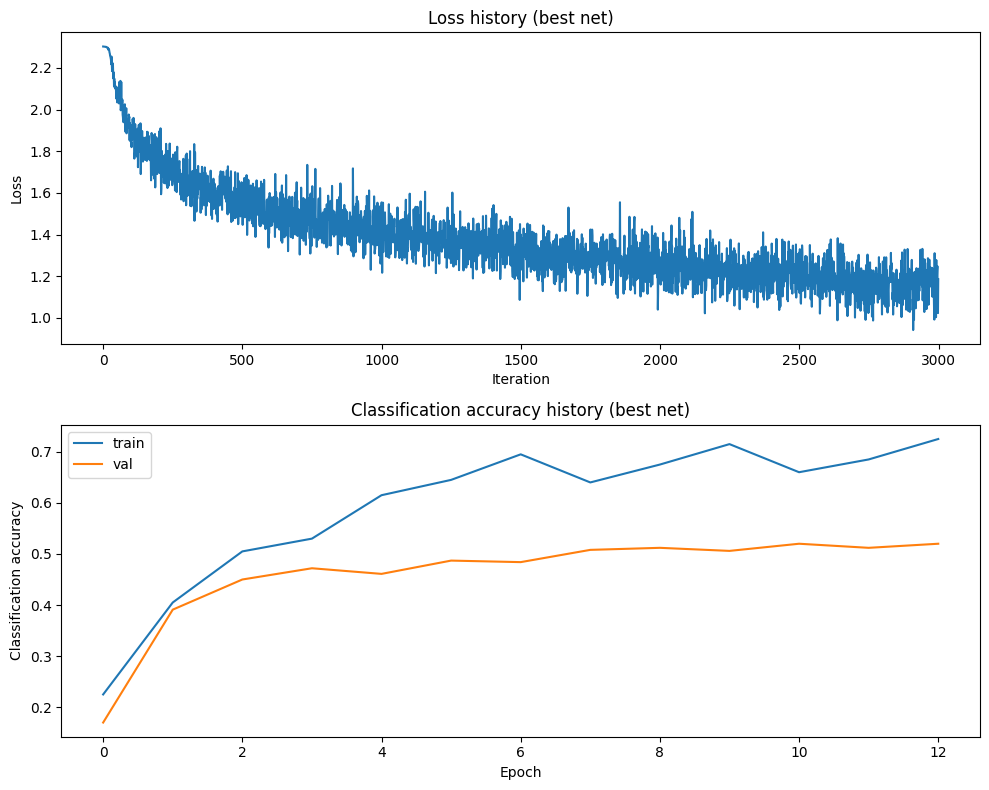

In [12]:
# графики обучения лучшей модели
plt.subplot(2, 1, 1)
plt.plot(best_stats['loss_history'])
plt.title('Loss history (best net)')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(best_stats['train_acc_history'], label='train')
plt.plot(best_stats['val_acc_history'], label='val')
plt.title('Classification accuracy history (best net)')
plt.xlabel('Epoch')
plt.ylabel('Classification accuracy')
plt.legend()
plt.tight_layout()
plt.show()

#### Accuracy лучшей модели на тестовой выборке

In [13]:
test_acc = (best_net.predict(X_test) == y_test).mean()
print('Test accuracy: ', test_acc)

Test accuracy:  0.522


#### Визуализация весов первого слоя

Веса первого слоя: модель по умолчанию


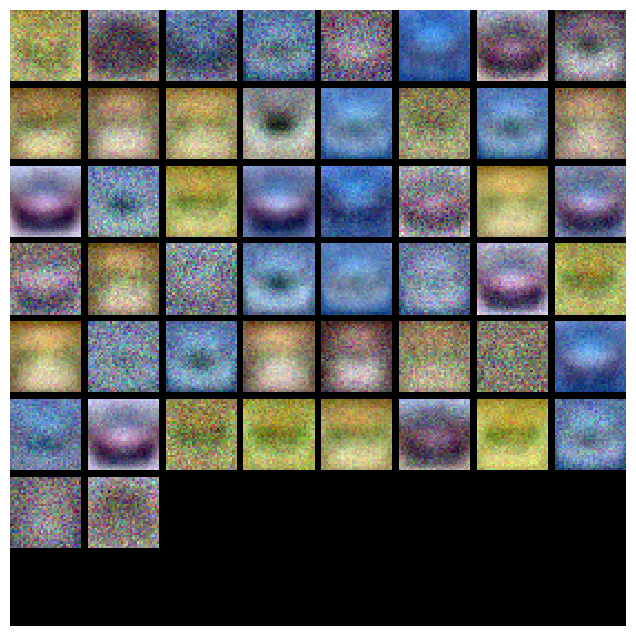

Веса первого слоя: лучшая модель


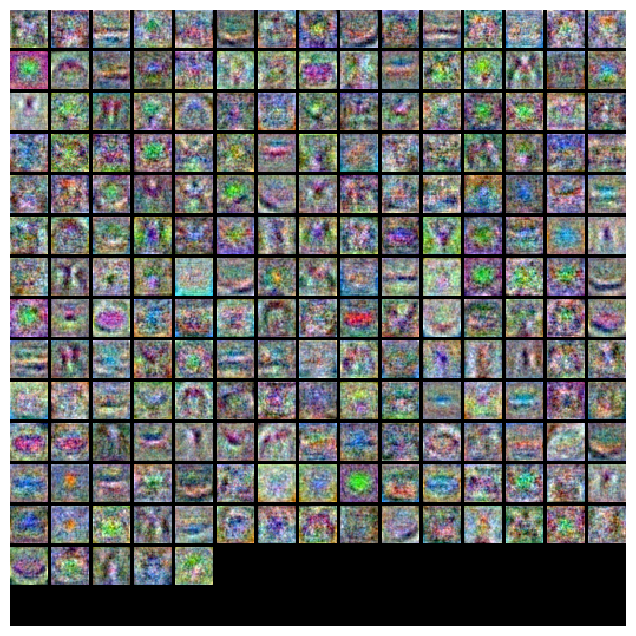

In [14]:
def show_net_weights(net):
    # каждый столбец W1 (3072 числа) - это "шаблон" одного скрытого нейрона,
    # переводим его обратно в картинку 32x32x3
    W1 = net.params['W1']
    W1 = W1.reshape(32, 32, 3, -1).transpose(3, 0, 1, 2)
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.gca().axis('off')
    plt.show()

print('Веса первого слоя: модель по умолчанию')
show_net_weights(baseline_net)
print('Веса первого слоя: лучшая модель')
show_net_weights(best_net)

Сделайте выводы по результатам работы.

### Выводы

1. Реализована двухслойная полносвязная сеть `TwoLayerNet` (FC → ReLU → FC → softmax) с L2-регуляризацией:
   прямой проход, функция потерь (cross-entropy), обратный проход (backprop), обучение мини-батчевым SGD и предсказание.
2. Проверка на модельных данных пройдена: ошибка scores ≈ 3.7e-8, ошибка loss ≈ 1.8e-13,
   относительная ошибка аналитических градиентов относительно численных ≤ 3.6e-9 для W1, b1, W2, b2;
   на игрушечных данных loss за 100 итераций упал до ≈ 0.017 (< 0.02).
3. С параметрами по умолчанию (hidden=50, lr=1e-4, 1000 итераций) accuracy на валидации ≈ 0.28:
   шаг слишком маленький, и сеть недообучена - loss почти не успевает уменьшиться.
4. После перебора гиперпараметров лучшая модель: hidden=200, learning_rate=1e-3, reg=0.05, 3000 итераций.
   Accuracy на валидации ≈ 0.54, на тестовой выборке ≈ 0.52. Это заметно лучше, чем в ЛР 1 (kNN ≈ 0.35, линейный SVM ≈ 0.36 на тесте).
5. Больше всего на качество влияет скорость обучения; увеличение скрытого слоя (100 → 200) даёт ещё ≈ 2%.
   Сильная регуляризация немного снижает разрыв train/val, но при небольшом числе итераций слегка уменьшает accuracy.
6. По графикам лучшей модели: loss плавно снижается с 2.3 до ≈ 1.2, accuracy на всей обучающей выборке ≈ 0.62, на val ≈ 0.54 -
   есть небольшое переобучение, которое можно уменьшить регуляризацией или dropout.
7. Веса первого слоя модели по умолчанию - размытые цветовые пятна (фон, "небо", "земля"), сеть выучила только
   общий цвет. У лучшей модели веса более детальные: видны контуры, края и цветовые шаблоны объектов.